# HM-RNN–inspired multiscale model (ETH hourly)

The original **HM-RNN** (Chung et al., ICML 2016) uses boundary detectors and custom cells. This notebook uses a **multiscale hierarchical** approximation:

- **Fast branch:** LSTM on every timestep.
- **Slow branch:** pooled sequence → LSTM → upsampled to match length.
- **Merge** → LSTM head → next close (regression).

**Metrics:** MSE, RMSE, MAE, MAPE. **Confusion matrix:** 2×2 **direction** (up vs down vs last close) — standard when you want a CM for price forecasting.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import confusion_matrix, mean_absolute_error, mean_squared_error
from sklearn.preprocessing import MinMaxScaler

# Hyperparameters (aligned with stacked LSTM / Parth runs)
WINDOW = 60
EPOCHS = 10
BATCH_SIZE = 32
PATIENCE = 15
RANDOM_SEED = 42

# Find eth_hourly.csv whether kernel cwd is ForeQast/ or HMRNN/
_cwd = Path.cwd().resolve()
if (_cwd / "eth_hourly.csv").exists():
    CSV_PATH = _cwd / "eth_hourly.csv"
elif (_cwd.parent / "eth_hourly.csv").exists():
    CSV_PATH = _cwd.parent / "eth_hourly.csv"
else:
    raise FileNotFoundError(
        "Place eth_hourly.csv in the ForeQast project root, or open Jupyter from that folder."
    )
CSV_PATH = str(CSV_PATH)
print("Using:", CSV_PATH)

Using: /Users/rishinatarajan/ACM Folder/ACM Research ForeQast/ForeQast/eth_hourly.csv


In [2]:
def set_seed(seed: int = RANDOM_SEED) -> None:
    np.random.seed(seed)
    tf.random.set_seed(seed)


def load_and_split_data(csv_path: str):
    df = pd.read_csv(csv_path, parse_dates=["Date"])
    df = df.sort_values("Date").reset_index(drop=True)
    close = df["close"].values.reshape(-1, 1)

    n = len(close)
    train_end = int(n * 0.80)
    val_end = int(n * 0.85)

    train_raw = close[:train_end]
    val_raw = close[train_end:val_end]
    test_raw = close[val_end:]

    scaler = MinMaxScaler()
    train = scaler.fit_transform(train_raw)
    val = scaler.transform(val_raw)
    test = scaler.transform(test_raw)

    return train, val, test, scaler, df


def make_windows(data: np.ndarray, window: int):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i - window : i])
        y.append(data[i, 0])
    return np.array(X), np.array(y).reshape(-1, 1)


def build_hmrnn_inspired_model(window: int) -> tf.keras.Model:
    inp = tf.keras.layers.Input(shape=(window, 1))

    fast = tf.keras.layers.LSTM(64, return_sequences=True)(inp)
    fast = tf.keras.layers.Dropout(0.2)(fast)

    slow_in = tf.keras.layers.AveragePooling1D(pool_size=2)(inp)
    slow = tf.keras.layers.LSTM(64, return_sequences=True)(slow_in)
    slow = tf.keras.layers.Dropout(0.2)(slow)
    slow = tf.keras.layers.UpSampling1D(size=2)(slow)

    merged = tf.keras.layers.Concatenate(axis=-1)([fast, slow])
    merged = tf.keras.layers.LSTM(32)(merged)
    merged = tf.keras.layers.Dropout(0.2)(merged)
    out = tf.keras.layers.Dense(16, activation="relu")(merged)
    out = tf.keras.layers.Dense(1)(out)

    model = tf.keras.Model(inp, out)
    model.compile(optimizer="adam", loss="mse", metrics=["mae"])
    return model


def mape(y_true: np.ndarray, y_pred: np.ndarray, eps: float = 1e-8) -> float:
    y_true = np.asarray(y_true).ravel()
    y_pred = np.asarray(y_pred).ravel()
    return float(np.mean(np.abs((y_true - y_pred) / (np.abs(y_true) + eps))) * 100.0)


def direction_confusion_matrix(y_true_usd, pred_usd, last_close_usd):
    actual_up = (y_true_usd.ravel() - last_close_usd.ravel()) > 0
    pred_up = (pred_usd.ravel() - last_close_usd.ravel()) > 0
    labels = ["Down", "Up"]
    cm = confusion_matrix(actual_up.astype(int), pred_up.astype(int), labels=[0, 1])
    return cm, labels


def plot_confusion_matrix(cm, labels, save_path=None):
    fig, ax = plt.subplots(figsize=(5, 4))
    im = ax.imshow(cm, interpolation="nearest", cmap=plt.cm.Blues)
    ax.figure.colorbar(im, ax=ax)
    ax.set(
        xticks=np.arange(cm.shape[1]),
        yticks=np.arange(cm.shape[0]),
        xticklabels=labels,
        yticklabels=labels,
        ylabel="Actual direction",
        xlabel="Predicted direction",
        title="Direction confusion matrix (next hour vs last close)",
    )
    plt.setp(ax.get_xticklabels(), rotation=0, ha="center")
    thresh = cm.max() / 2.0 if cm.size else 0
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j,
                i,
                format(cm[i, j], "d"),
                ha="center",
                va="center",
                color="white" if cm[i, j] > thresh else "black",
            )
    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150)
        print("Saved:", save_path)
    plt.show()

In [3]:
set_seed()

train, val, test, scaler, df = load_and_split_data(CSV_PATH)

X_train, y_train = make_windows(train, WINDOW)
X_val, y_val = make_windows(val, WINDOW)
X_test, y_test = make_windows(test, WINDOW)

val_end_idx = int(len(df) * 0.85)
test_start = val_end_idx
last_close_test = np.array(
    [df["close"].iloc[test_start + WINDOW + k - 1] for k in range(len(y_test))],
    dtype=np.float64,
).reshape(-1, 1)

X_train.shape, X_test.shape, y_test.shape

((2360, 60, 1), (394, 60, 1), (394, 1))

In [4]:
model = build_hmrnn_inspired_model(WINDOW)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 60, 1)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling1d   │ (None, 30, 1)     │          0 │ input_layer[0][0] │
│ (AveragePooling1D)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_1 (LSTM)       │ (None, 30, 64)    │     16,896 │ average_pooling1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm (LSTM)         │ (None, 60, 64)    │     16,896 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 30, 64)    │          0 │ lstm_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 60, 64)    │          0 │ lstm[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ up_sampling1d       │ (None, 60, 64)    │          0 │ dropout_1[0][0]   │
│ (UpSampling1D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 60, 128)   │          0 │ dropout[0][0],    │
│ (Concatenate)       │                   │            │ up_sampling1d[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ lstm_2 (LSTM)       │ (None, 32)        │     20,608 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 32)        │          0 │ lstm_2[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 16)        │        528 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 1)         │         17 │ dense[0][0]       │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 54,945 (214.63 KB)

 Trainable params: 54,945 (214.63 KB)

 Non-trainable params: 0 (0.00 B)

In [5]:
early = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=PATIENCE, restore_best_weights=True
)
history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early],
    verbose=1,
)
print(f"Training stopped at epoch {len(history.history['loss'])}")

Epoch 1/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 3s 22ms/step - loss: 0.0127 - mae: 0.0672 - val_loss: 0.0027 - val_mae: 0.0377
Epoch 2/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0033 - mae: 0.0362 - val_loss: 0.0043 - val_mae: 0.0518
Epoch 3/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0031 - mae: 0.0345 - val_loss: 0.0018 - val_mae: 0.0320
Epoch 4/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0025 - mae: 0.0315 - val_loss: 0.0034 - val_mae: 0.0456
Epoch 5/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0024 - mae: 0.0302 - val_loss: 0.0025 - val_mae: 0.0374
Epoch 6/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0019 - mae: 0.0281 - val_loss: 0.0032 - val_mae: 0.0442
Epoch 7/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.0020 - mae: 0.0278 - val_loss: 0.0033 - val_mae: 0.0464
Epoch 8/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 22ms/step - loss: 0.0020 - mae: 0.0285 - val_loss: 0.0042 - val_mae: 0.0549
Epoch 9/10
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 21ms/step - loss: 0.001

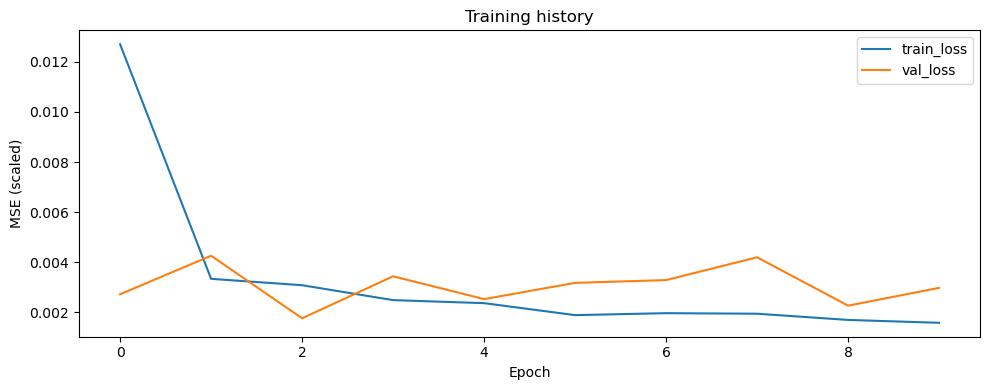

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(history.history["loss"], label="train_loss")
plt.plot(history.history["val_loss"], label="val_loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (scaled)")
plt.legend()
plt.title("Training history")
plt.tight_layout()
plt.show()

In [7]:
pred_test = model.predict(X_test, verbose=0)
y_test_usd = scaler.inverse_transform(y_test)
pred_usd = scaler.inverse_transform(pred_test)

mse = mean_squared_error(y_test_usd, pred_usd)
rmse = float(np.sqrt(mse))
mae = mean_absolute_error(y_test_usd, pred_usd)
mape_val = mape(y_test_usd, pred_usd)

print("--- Test set (regression) ---")
print(f"MSE:   {mse:,.2f} USD²")
print(f"RMSE:  {rmse:,.2f} USD")
print(f"MAE:   {mae:,.2f} USD")
print(f"MAPE:  {mape_val:.2f}%")

--- Test set (regression) ---
MSE:   67,441.68 USD²
RMSE:  259.70 USD
MAE:   193.43 USD
MAPE:  6.64%


In [ ]:
cm, dir_labels = direction_confusion_matrix(y_test_usd, pred_usd, last_close_test)
print("Labels (rows=actual, cols=predicted):", dir_labels)
print(cm)

out_dir = Path(CSV_PATH).parent
if (out_dir / "HMRNN").is_dir():
    plot_path = out_dir / "HMRNN" / "hmrnn_direction_confusion_matrix.png"
else:
    plot_path = Path.cwd() / "hmrnn_direction_confusion_matrix.png"
plot_confusion_matrix(cm, dir_labels, save_path=str(plot_path))

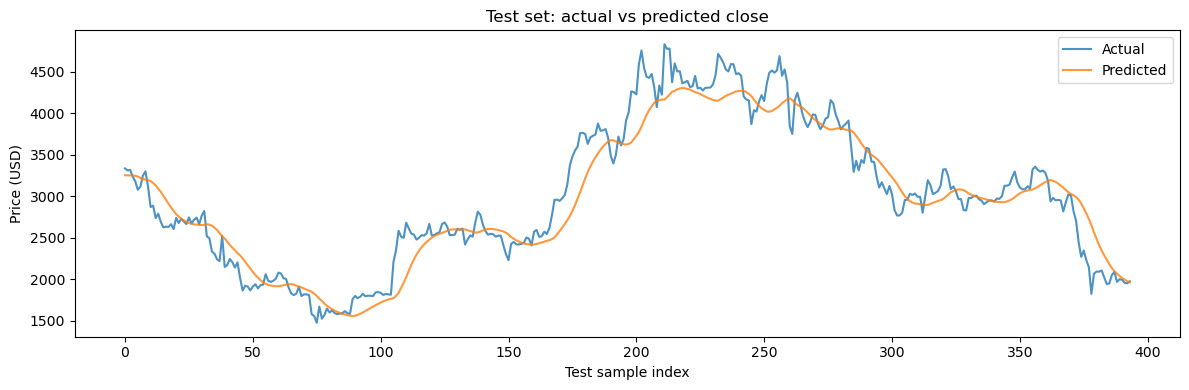

In [8]:
# Optional: actual vs predicted (test set)
plt.figure(figsize=(12, 4))
plt.plot(y_test_usd, label="Actual", alpha=0.8)
plt.plot(pred_usd, label="Predicted", alpha=0.8)
plt.xlabel("Test sample index")
plt.ylabel("Price (USD)")
plt.legend()
plt.title("Test set: actual vs predicted close")
plt.tight_layout()
plt.show()